# THP-1 Perturb-seq: from H5AD contents to Figure 6 summaries

This notebook answers two questions: **what is actually stored in the expression file**, and **which calculations explain the scMINER Figure 6 workbook**? The sample is conventional CRISPRi **knockdown**, `GSM6858449`, not the conventional Cas9 knockout sample.

We inspect public data and redraw available summaries. We do **not** reproduce the complete scMINER workflow, run network inference, or compare SJARACNe versions. Prepared author inputs are missing, and the workbook's Figure 6a ROC export is incomplete.

Sources: [GEO sample](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM6858449), [Yao et al.](https://www.nature.com/articles/s41587-023-01964-9), [scMINER paper](https://www.nature.com/articles/s41467-025-59620-6), and [pinned author code](https://github.com/jyyulab/scMINER_analysis/tree/c39f0aaffc22be81ae425adf9e7617504ae9ee33/network_inference/CROP_Seq_GRN_evaluation/Yao_Regev_Cleary).

## 1. Setup and external files

Install `requirements.txt` into the Python environment selected as this notebook's kernel. Set `SJARACNE_THP1_DATA` if your files are elsewhere. This setting accepts either the sample folder or its `Perturb-seq` parent.

No input files are modified. Expression is opened with `backed='r'`, keeping the large sparse matrices on disk. Backed mode still loads cell/gene metadata. Avoid `adata.X.toarray()` or a full `to_memory()`: one dense float64 matrix here would occupy about 8.9 GiB. [AnnData reading documentation](https://anndata.readthedocs.io/en/stable/generated/anndata.io.read_h5ad.html).

In [1]:
from pathlib import Path
from collections import Counter
from importlib.metadata import version
import csv
import gzip
import os
import sys

import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import sparse
from scipy.integrate import trapezoid
from openpyxl import load_workbook
from IPython.display import display

pd.set_option('display.max_rows', 12)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

default_data_dir = (r'E:\SpaGRN\SJARACNe\Perturb-seq\THP1_GSM6858449' if os.name == 'nt'
                    else '/mnt/e/SpaGRN/SJARACNe/Perturb-seq/THP1_GSM6858449')
DATA_DIR = Path(os.environ.get('SJARACNE_THP1_DATA', default_data_dir)).expanduser()
H5AD_NAME = 'GSM6858449_KD_conventional.h5ad'
if not (DATA_DIR / H5AD_NAME).is_file() and (DATA_DIR / 'THP1_GSM6858449' / H5AD_NAME).is_file():
    DATA_DIR = DATA_DIR / 'THP1_GSM6858449'
H5AD_PATH = DATA_DIR / H5AD_NAME
ASSIGNMENT_PATH = DATA_DIR / 'GSM6858449_KD_conventional_perturbations.txt.gz'
EFFECT_PATH = DATA_DIR / 'GSM6858449_KD_conventional_FRPerturb_effect_sizes.csv.gz'
WORKBOOK_PATH = DATA_DIR / 'Source_Data_Figure_6.xlsx'
AUTHOR_COMMIT = 'c39f0aaffc22be81ae425adf9e7617504ae9ee33'
AUTHOR_CODE_URL = f'https://github.com/jyyulab/scMINER_analysis/blob/{AUTHOR_COMMIT}/network_inference/CROP_Seq_GRN_evaluation/Yao_Regev_Cleary'

print('Data directory:', DATA_DIR)
print('Python:', sys.version.split()[0])
display(pd.Series({name: version(name) for name in ['anndata', 'h5py', 'numpy', 'pandas', 'scipy', 'matplotlib', 'openpyxl']}, name='version').to_frame())
for required in [H5AD_PATH, WORKBOOK_PATH]:
    if not required.is_file():
        raise FileNotFoundError(f'Missing {required}. Set SJARACNE_THP1_DATA to your downloaded sample folder.')

Data directory: E:\SpaGRN\SJARACNe\Perturb-seq\THP1_GSM6858449
Python: 3.13.0


,version
anndata,0.12.14
h5py,3.16.0
numpy,2.4.4
pandas,2.3.3
scipy,1.17.1
matplotlib,3.10.9
openpyxl,3.1.5


In [2]:
input_roles = {
    H5AD_NAME: 'GEO expression and cell metadata',
    ASSIGNMENT_PATH.name: 'GEO target-by-cell guide counts',
    EFFECT_PATH.name: 'GEO conventional-screen FR-Perturb effects',
    WORKBOOK_PATH.name: 'Extracted scMINER source-data workbook',
    'scMINER_Source_Data.zip': 'Published scMINER source-data archive',
    'DE_compute.Rmd': 'Author differential-expression code',
    'DE_plot_ROC.Rmd': 'Author ranking/evaluation code',
    'process_nets_compute_GSEA.Rmd': 'Author network processing code',
}
display(pd.DataFrame([{'file': name, 'role': role, 'exists': (DATA_DIR / name).is_file(),
                       'MiB': round((DATA_DIR / name).stat().st_size / 2**20, 2) if (DATA_DIR / name).is_file() else np.nan}
                      for name, role in input_roles.items()]))

,file,role,exists,MiB
0,GSM6858449_KD_conventional.h5ad,GEO expression and cell metadata,True,1139.21
1,GSM6858449_KD_conventional_perturbations.txt.gz,GEO target-by-cell guide counts,True,0.56
2,GSM6858449_KD_conventional_FRPerturb_effect_si...,GEO conventional-screen FR-Perturb effects,True,64.77
3,Source_Data_Figure_6.xlsx,Extracted scMINER source-data workbook,True,1.54
4,scMINER_Source_Data.zip,Published scMINER source-data archive,True,357.66
5,DE_compute.Rmd,Author differential-expression code,True,0.00
6,DE_plot_ROC.Rmd,Author ranking/evaluation code,True,0.03
7,process_nets_compute_GSEA.Rmd,Author network processing code,True,0.04


## 2. Understand the AnnData container

Rows are cells; columns are expression features. `obs` describes cells, `var` describes genes, `X` holds the working expression matrix, and `raw.X` is a separate stored matrix. The name `raw` alone does not prove that values are counts; we test this below. `layers`, `obsm`, and `uns` may contain other matrices, embeddings, and metadata, but this particular file has none.

With the tested AnnData version, this legacy H5AD exposes numeric strings in `var_names`. **Use `var['features']` for gene lookup**, not those numeric identifiers. Check `raw.var` separately before matching matrix columns. We do not rewrite the source file to fix its encoding.

In [3]:
adata = ad.read_h5ad(H5AD_PATH, backed='r')
obs = adata.obs.copy()
gene_symbols = adata.var['features'].astype(str)
if adata.raw is None:
    raise ValueError('The expected raw matrix is absent.')
raw_symbol_column = 'features' if 'features' in adata.raw.var else '_index'
raw_symbols = adata.raw.var[raw_symbol_column].astype(str)
print(adata)
print('Cells x genes:', adata.shape)
print('Backed:', adata.isbacked, '| X type:', type(adata.X).__name__)
print('Dense float64 GiB per matrix:', round(adata.n_obs * adata.n_vars * 8 / 2**30, 2))
print('obs columns:', list(obs.columns))
print('layers / obsm / uns:', list(adata.layers), list(adata.obsm), list(adata.uns))
print('First var_names:', list(adata.var_names[:5]))
print('First gene symbols:', gene_symbols.iloc[:5].tolist())
assert adata.obs_names.is_unique and gene_symbols.is_unique
assert np.array_equal(gene_symbols.to_numpy(), raw_symbols.to_numpy())
display(adata.var.head())
display(obs[['Biological_replicate', 'Total_RNA_count', 'Total_unique_genes', 'Percent_mitochondrial_reads',
             'Guides_collapsed_by_gene', 'Total_number_of_guides', '10X_channel']].head())

AnnData object with n_obs × n_vars = 66283 × 18017 backed at 'E:\\SpaGRN\\SJARACNe\\Perturb-seq\\THP1_GSM6858449\\GSM6858449_KD_conventional.h5ad'
    obs: 'Biological_replicate', 'Total_RNA_count', 'Total_unique_genes', 'Percent_mitochondrial_reads', 'Guides', 'Guides_collapsed_by_gene', 'Total_number_of_guides', '10X_channel', 'S_score', 'G2M_score', 'Cell_cycle_phase'
    var: '_index', 'features'
Cells x genes: (66283, 18017)
Backed: True | X type: _CSRDataset
Dense float64 GiB per matrix: 8.9
obs columns: ['Biological_replicate', 'Total_RNA_count', 'Total_unique_genes', 'Percent_mitochondrial_reads', 'Guides', 'Guides_collapsed_by_gene', 'Total_number_of_guides', '10X_channel', 'S_score', 'G2M_score', 'Cell_cycle_phase']
layers / obsm / uns: [] [] []
First var_names: ['0', '1', '2', '3', '4']
First gene symbols: ['AL627309.1', 'AL669831.5', 'FAM87B', 'LINC00115', 'FAM41C']


,_index,features
0,AL627309.1,AL627309.1
1,AL669831.5,AL669831.5
2,FAM87B,FAM87B
3,LINC00115,LINC00115
4,FAM41C,FAM41C


,Biological_replicate,Total_RNA_count,Total_unique_genes,Percent_mitochondrial_reads,Guides_collapsed_by_gene,Total_number_of_guides,10X_channel
AAACCCAGTAGACAAT-1_1,Run_1,6010.0,2262,4.742097,RAC1,1.0,Low_MOI_1
AAACCCAGTTACACTG-1_1,Run_1,6619.0,2493,6.889258,SUOX,1.0,Low_MOI_1
AAACGAAAGGCATCTT-1_1,Run_1,27699.0,5543,13.314560,TNFSF15,1.0,Low_MOI_1
AAACGAATCAATGTCG-1_1,Run_1,7817.0,2747,4.439043,DUSP1--ARPC4-TTLL3,2.0,Low_MOI_1
AAACGAATCTAGAACC-1_1,Run_1,18500.0,4358,6.275676,TNFSF15,1.0,Low_MOI_1


In [4]:
preview_genes = ['MYD88', 'STAT1', 'IL1B', 'RAC1', 'SUOX', 'DUSP1']
preview_positions = np.flatnonzero(gene_symbols.isin(preview_genes).to_numpy())
small_expression = adata[:8, preview_positions].X
small_raw_expression = adata[:7, preview_positions].raw.X
# Densifying ONLY this tiny cell-by-gene slice is safe.
display(pd.DataFrame(small_expression.toarray(), index=adata.obs_names[:8],
                     columns=gene_symbols.iloc[preview_positions].to_numpy()))
display(obs[['Total_RNA_count', 'Total_unique_genes', 'Percent_mitochondrial_reads']].describe())
display(obs['Biological_replicate'].value_counts().rename('cells').to_frame())

,IL1B,STAT1,MYD88,DUSP1,RAC1,SUOX
AAACCCAGTAGACAAT-1_1,0.979789,2.396381,0.000000,0.000000,0.000000,0.000000
AAACCCAGTTACACTG-1_1,3.339125,0.000000,0.000000,0.000000,2.309046,0.000000
AAACGAAAGGCATCTT-1_1,0.543514,1.673780,0.308237,0.000000,1.260495,0.000000
AAACGAATCAATGTCG-1_1,0.000000,1.269346,0.823852,0.000000,1.269346,0.000000
AAACGAATCTAGAACC-1_1,0.432133,2.266818,0.732888,0.000000,1.565232,0.000000
AAACGCTCAAATCGTC-1_1,4.896974,1.673946,0.674437,0.893796,1.474819,0.000000
AAACGCTCAAGACAAT-1_1,1.616156,0.852101,0.000000,0.370314,1.305392,0.000000
AAACGCTGTCCGAAAG-1_1,3.785485,1.473351,0.514479,0.000000,1.305915,0.514479


,Total_RNA_count,Total_unique_genes,Percent_mitochondrial_reads
count,66283.000000,66283.000000,66283.000000
mean,14692.396074,3542.752787,7.546645
std,10024.332197,1375.222876,5.358872
min,504.000000,245.000000,0.000000
25%,7503.500000,2554.000000,5.124770
50%,12412.000000,3460.000000,6.611481
75%,19337.500000,4453.000000,8.372528
max,105842.000000,8917.000000,87.777778


,cells
Biological_replicate,
Run_1,38329
Run_2,27954


## 3. Guide assignments, targeted genes, and controls

The conventional low-MOI design aims for one guide per cell, but it is not a strict maximum. Split assignment strings on the literal separator `--`, **not** on single hyphens: `ARPC4-TTLL3` is one target label. A label such as `CEBPB--CEBPB` represents two guides assigned to the same gene. One guide and one distinct targeted gene are different criteria.

`non-targeting` guides have no intended genomic target; `safe-targeting` guides target designated intergenic regions. Keep them separate. A control guide plus a real target is not a clean control. Assignment does not establish successful knockdown.

In [5]:
labels = obs['Guides_collapsed_by_gene'].astype(str)
tokens = labels.str.split('--')
guide_count = pd.to_numeric(obs['Total_number_of_guides'], errors='raise').astype(int)
distinct_targets = tokens.map(lambda values: len(set(values)))
control_labels = {'non-targeting', 'safe-targeting'}

def classify_assignment(values):
    unique = set(values)
    biological = unique - control_labels
    controls = unique & control_labels
    if unique == {'non-targeting'}:
        return 'Non-targeting only'
    if unique == {'safe-targeting'}:
        return 'Safe-targeting only'
    if not biological:
        return 'Mixed control types'
    if controls:
        return 'Control plus biological target'
    return 'One biological target' if len(biological) == 1 else 'Multiple biological targets'

assignment_category = tokens.map(classify_assignment)
assert tokens.map(len).eq(guide_count).all()
assert obs['Guides'].astype(str).str.split('--').map(len).eq(guide_count).all()
display(guide_count.value_counts().sort_index().rename('cells').to_frame())
display(assignment_category.value_counts().rename('cells').to_frame())
display(pd.Series({
    'Single guide': int(guide_count.eq(1).sum()),
    'One distinct target label': int(distinct_targets.eq(1).sum()),
    'Multiple guides, one distinct target label': int((guide_count.gt(1) & distinct_targets.eq(1)).sum()),
    'Exact non-targeting label': int(labels.eq('non-targeting').sum()),
    'Non-targeting only, including repeated guides': int(assignment_category.eq('Non-targeting only').sum()),
}, name='cells').to_frame())
display(obs.loc[guide_count.gt(1) & distinct_targets.eq(1),
                ['Guides_collapsed_by_gene', 'Total_number_of_guides']].head(8))

,cells
Total_number_of_guides,
1,59840
2,5172
3,773
4,268
5,131
6,54
7,25
8,4
9,8


,cells
Guides_collapsed_by_gene,
One biological target,54886
Multiple biological targets,5233
Non-targeting only,2645
Safe-targeting only,2354
Control plus biological target,1137
Mixed control types,28


,cells
Single guide,59840
One distinct target label,59885
"Multiple guides, one distinct target label",45
Exact non-targeting label,2636
"Non-targeting only, including repeated guides",2645


,Guides_collapsed_by_gene,Total_number_of_guides
AATCGACAGTACTGGG-1_1,non-targeting--non-targeting,2.0
GATCATGGTACCTTCC-1_1,non-targeting--non-targeting,2.0
ATGTCTTTCTGGCCTT-1_1,non-targeting--non-targeting,2.0
CCTTTGGGTAGCGAGT-1_1,non-targeting--non-targeting,2.0
GTAGTACCAGACCAGA-1_1,non-targeting--non-targeting,2.0
TAGGTTGAGGACTGGT-1_1,CEBPB--CEBPB,2.0
GAGTTGTTCTTCGACC-1_1,CEBPB--CEBPB,2.0
GAGTTACTCTCAACGA-1_1,IRAK4--IRAK4,2.0


Strict single-guide NT cells: 2636
Strict single-guide safe-targeting cells: 2352


Biological_replicate,Run_1,Run_2
Guides_collapsed_by_gene,,
Control plus biological target,498,639
Mixed control types,12,16
Multiple biological targets,2437,2796
Non-targeting only,1589,1056
One biological target,32433,22453
Safe-targeting only,1360,994


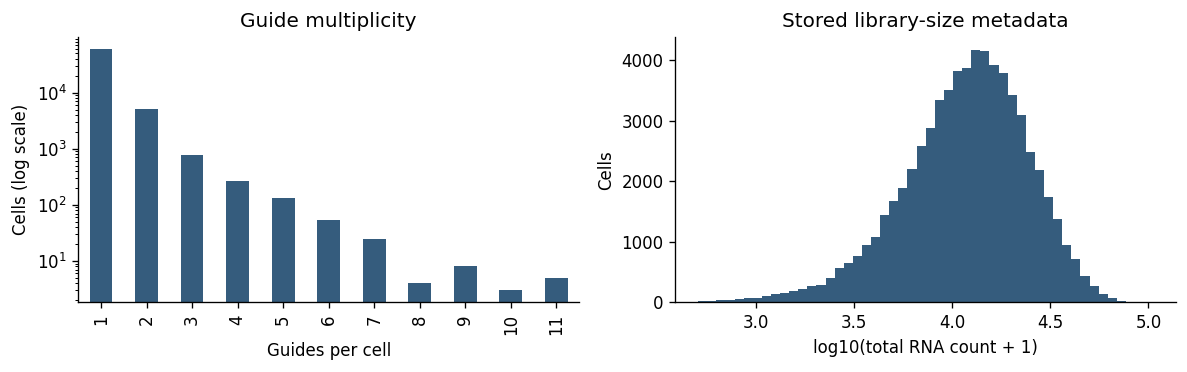

In [6]:
clean_nt = guide_count.eq(1) & labels.eq('non-targeting')
clean_safe = guide_count.eq(1) & labels.eq('safe-targeting')
print('Strict single-guide NT cells:', int(clean_nt.sum()))
print('Strict single-guide safe-targeting cells:', int(clean_safe.sum()))
display(pd.crosstab(assignment_category, obs['Biological_replicate']))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
guide_count.value_counts().sort_index().plot.bar(ax=axes[0], color='#355c7d')
axes[0].set(xlabel='Guides per cell', ylabel='Cells (log scale)', yscale='log', title='Guide multiplicity')
axes[1].hist(np.log10(pd.to_numeric(obs['Total_RNA_count']) + 1), bins=50, color='#355c7d')
axes[1].set(xlabel='log10(total RNA count + 1)', ylabel='Cells', title='Stored library-size metadata')
fig.tight_layout()
plt.show()

## 4. Verify counts and normalization on a bounded sample

We test whether `raw.X` is integer-valued and whether its row totals agree with the stored library sizes. We then compare `X` with `ln(1 + 10,000 × count / cell_total)`. This is a test of sampled cells, not an exhaustive proof about every value.

The tested file's `X` is already natural-log transformed after 10,000-count scaling. Do not normalize or log it again. The scMINER preparation described in the paper uses **log2(1 + CPM)**; that is a different scale. Derive it from counts when illustrating that calculation rather than silently treating `X` as the paper's prepared input.

In [7]:
test_rows = np.unique(np.linspace(0, adata.n_obs - 1, 32, dtype=int))
raw_sample = adata.raw.X[test_rows, :].tocsr()
x_sample = adata.X[test_rows, :].tocsr()
row_totals = np.asarray(raw_sample.sum(axis=1)).ravel()
assert np.all(row_totals > 0)
expected_x = raw_sample.multiply((10_000 / row_totals)[:, None]).tocsr()
expected_x.data = np.log1p(expected_x.data)
difference = x_sample - expected_x
max_error = float(np.max(np.abs(difference.data))) if difference.nnz else 0.0
checks = {
    'Sampled cells': len(test_rows),
    'Sampled nonzero counts': raw_sample.nnz,
    'Integer-valued sampled raw entries': bool(np.all(raw_sample.data == np.rint(raw_sample.data))),
    'Raw row sums match Total_RNA_count': bool(np.allclose(row_totals, pd.to_numeric(obs.iloc[test_rows]['Total_RNA_count']))),
    'Detected genes match Total_unique_genes': bool(np.array_equal(np.diff(raw_sample.indptr), pd.to_numeric(obs.iloc[test_rows]['Total_unique_genes']))),
    'Maximum |X - ln(1+normalized counts)|': max_error,
}
display(pd.Series(checks, name='result').to_frame())
assert checks['Integer-valued sampled raw entries']
assert checks['Raw row sums match Total_RNA_count']
assert checks['Detected genes match Total_unique_genes']
assert max_error < 1e-10
del raw_sample, x_sample, expected_x, difference

,result
Sampled cells,32
Sampled nonzero counts,118280
Integer-valued sampled raw entries,True
Raw row sums match Total_RNA_count,True
Detected genes match Total_unique_genes,True
Maximum |X - ln(1+normalized counts)|,0.0


### An illustrative knockdown comparison

Choose a gene below. We compare at most 200 single-guide cells per group with NT controls, using **counts-derived** linear CPM and log2(1+CPM). This is an illustrative subsample before the authors' QC and eligibility filtering, not `scran::findMarkers`, not a reproduction of their effect sizes, and not a benchmark truth label.

A reduction in mean linear RNA expression is not the fraction of successfully knocked-down cells and does not measure protein depletion. A difference between mean log-transformed values cannot be converted into that percentage with a simple fold-change formula. Biological replicates and other cell-state effects also remain unadjusted here.

,cells,mean_raw_count,mean_CPM,mean_log2_CPM_plus1
group,,,,
NT,200,0.525000,40.751636,2.404860
MYD88,99,0.141414,7.527242,0.564504


Illustrative change in mean linear CPM (% reduction): 81.53


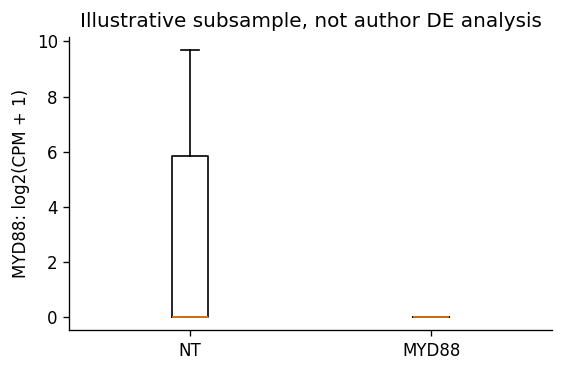

In [8]:
EXAMPLE_GENE = 'MYD88'
MAX_CELLS_PER_GROUP = 200
rng = np.random.default_rng(42)
gene_positions = np.flatnonzero(raw_symbols.eq(EXAMPLE_GENE).to_numpy())
if len(gene_positions) != 1:
    raise ValueError(f'{EXAMPLE_GENE}: expected one exact expression-symbol match, found {len(gene_positions)}.')
example_groups = {'NT': clean_nt, EXAMPLE_GENE: guide_count.eq(1) & labels.eq(EXAMPLE_GENE)}
example_frames = []
for group_name, mask in example_groups.items():
    available_rows = np.flatnonzero(mask.to_numpy())
    if len(available_rows) == 0:
        raise ValueError(f'No single-guide cells for {group_name}. Choose another EXAMPLE_GENE.')
    selected_rows = np.sort(rng.choice(available_rows, min(MAX_CELLS_PER_GROUP, len(available_rows)), replace=False))
    counts_block = adata.raw.X[selected_rows, :].tocsr()
    totals = np.asarray(counts_block.sum(axis=1)).ravel()
    own_counts = counts_block[:, int(gene_positions[0])].toarray().ravel()
    cpm = 1e6 * own_counts / totals
    example_frames.append(pd.DataFrame({'group': group_name, 'raw_count': own_counts, 'CPM': cpm,
                                        'log2_CPM_plus1': np.log2(1 + cpm)}))
    del counts_block
example_expression = pd.concat(example_frames, ignore_index=True)
example_summary = example_expression.groupby('group', sort=False).agg(
    cells=('raw_count', 'size'), mean_raw_count=('raw_count', 'mean'), mean_CPM=('CPM', 'mean'),
    mean_log2_CPM_plus1=('log2_CPM_plus1', 'mean'))
display(example_summary)
nt_mean = example_summary.loc['NT', 'mean_CPM']
reduction = 100 * (1 - example_summary.loc[EXAMPLE_GENE, 'mean_CPM'] / nt_mean) if nt_mean > 0 else np.nan
print('Illustrative change in mean linear CPM (% reduction):', round(reduction, 2))
fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.boxplot([frame['log2_CPM_plus1'].to_numpy() for frame in example_frames],
           tick_labels=list(example_groups), showfliers=False)
ax.set(ylabel=f'{EXAMPLE_GENE}: log2(CPM + 1)', title='Illustrative subsample, not author DE analysis')
fig.tight_layout()
plt.show()

## 5. The separate target-by-cell assignment matrix

The gzip TXT supplements the H5AD. Its rows are targets and its columns are cell barcodes. Values count guides assigned to that target, so they can be 2 or more. The header has barcodes **without an empty top-left field**; later rows add a leading target name. We stream rows instead of materializing all 600 × 66,283 values.

The example below keeps only a few cells, including repeated-guide examples, and checks matrix values against the metadata. Exact target labels may differ from modern expression symbols. An unmatched symbol is an annotation question, not proof that a gene is absent.

In [9]:
if ASSIGNMENT_PATH.is_file():
    repeated_rows = np.flatnonzero((guide_count.gt(1) & distinct_targets.eq(1)).to_numpy())[:3]
    assignment_rows = np.unique(np.concatenate([np.arange(6), repeated_rows]))
    selected_barcodes = adata.obs_names[assignment_rows].tolist()
    sampled_assignments = {}
    with gzip.open(ASSIGNMENT_PATH, 'rt') as handle:
        header_barcodes = handle.readline().rstrip('\r\n').split('\t')
        assert header_barcodes == adata.obs_names.tolist()
        for line in handle:
            target, values_text = line.rstrip('\r\n').split('\t', 1)
            values = np.fromstring(values_text, sep='\t', dtype=np.int16)
            assert len(values) == len(header_barcodes)
            if target in sampled_assignments:
                raise ValueError(f'Duplicate target row: {target}')
            sampled_assignments[target] = values[assignment_rows]
    assignment_preview = pd.DataFrame.from_dict(sampled_assignments, orient='index', columns=selected_barcodes)
    for local_index, row_index in enumerate(assignment_rows):
        expected = Counter(tokens.iloc[row_index])
        observed = assignment_preview.iloc[:, local_index]
        assert observed.eq([expected.get(target, 0) for target in observed.index]).all()
    assert np.array_equal(assignment_preview.sum(axis=0).to_numpy(), guide_count.iloc[assignment_rows].to_numpy())
    print('Matrix dimensions:', len(assignment_preview), 'targets x', len(header_barcodes), 'cells')
    print('Barcode order and sampled guide counts agree with the H5AD metadata.')
    nonzero_preview = assignment_preview.loc[assignment_preview.sum(axis=1).gt(0)]
    display(nonzero_preview)
    biological_targets = sorted(set(assignment_preview.index) - control_labels)
    unmatched_symbols = sorted(set(biological_targets) - set(gene_symbols))
    print('Noncontrol targets:', len(biological_targets), '| exact expression-symbol matches:', len(biological_targets) - len(unmatched_symbols))
    print('Unmatched labels:', len(unmatched_symbols), '| examples:', unmatched_symbols[:12])
else:
    print('Assignment TXT is absent; this optional section is skipped.')

Matrix dimensions: 600 targets x 66283 cells
Barcode order and sampled guide counts agree with the H5AD metadata.


,AAACCCAGTAGACAAT-1_1,AAACCCAGTTACACTG-1_1,AAACGAAAGGCATCTT-1_1,AAACGAATCAATGTCG-1_1,AAACGAATCTAGAACC-1_1,AAACGCTCAAATCGTC-1_1,AATCGACAGTACTGGG-1_1,GATCATGGTACCTTCC-1_1,ATGTCTTTCTGGCCTT-1_1
ARPC4-TTLL3,0,0,0,1,0,0,0,0,0
DUSP1,0,0,0,1,0,0,0,0,0
IL2RA,0,0,0,0,0,1,0,0,0
non-targeting,0,0,0,0,0,0,2,2,2
RAC1,1,0,0,0,0,0,0,0,0
SUOX,0,1,0,0,0,0,0,0,0
TNFSF15,0,0,1,0,1,0,0,0,0


Noncontrol targets: 598 | exact expression-symbol matches: 552
Unmatched labels: 46 | examples: ['ARPC4-TTLL3', 'ATP5D', 'C1orf106', 'C1orf141', 'CEBPA-AS1', 'CFTR', 'CR1', 'CRIPAK', 'CTBP1-AS2', 'DLG5-AS1', 'DPP10', 'DSG1']


## 6. What is the downloaded FR-Perturb CSV?

This conventional-screen table stores perturbed gene, downstream gene, estimated log-fold change, and q-value. It is an output of **Yao's FR-Perturb analysis**. scMINER's public Figure 6a code instead builds response labels using `scran::findMarkers` results. These analyses are not interchangeable.

We read a small preview only. The `KD_all` file, which combines conventional and pooled KD samples, is a different file and is not used here. A response of B after perturbing A can be indirect; it does not prove a direct A-to-B regulatory interaction.

In [10]:
if EFFECT_PATH.is_file():
    effect_preview = pd.read_csv(EFFECT_PATH, nrows=8)
    expected_columns = ['Perturbed_gene', 'Downstream_gene', 'Log_fold_change', 'qvalue']
    assert effect_preview.columns.tolist() == expected_columns
    display(effect_preview)
    print('This preview is not used to create Figure 6a truth labels.')
else:
    print('Conventional FR-Perturb CSV is absent; this optional preview is skipped.')

,Perturbed_gene,Downstream_gene,Log_fold_change,qvalue
0,A4GALT,A1BG,0.00390,0.98
1,A4GALT,A1BG-AS1,0.02300,0.54
2,A4GALT,A2M,-0.03800,0.59
3,A4GALT,A2M-AS1,-0.02000,0.86
4,A4GALT,A4GALT,0.03600,0.60
5,A4GALT,AAAS,0.02200,0.81
6,A4GALT,AACS,-0.00012,0.99
7,A4GALT,AADACL2,-0.00760,0.96


This preview is not used to create Figure 6a truth labels.


## 7. Inspect the Figure 6 source-data workbook

The workbook is an extracted member of the paper's source-data ZIP. It contains seven sheets and several kinds of summaries; do not assume every sheet represents the same THP-1 experiment. For example, later sheets contain cell-type, protein, and embedding columns.

We inspect the layout before assigning meaning to values. Figure 6a has a two-row header with three independent, side-by-side blocks: TP counts, EPR, and ROC coordinates. **A worksheet row is not one shared observation across those blocks.**

In [11]:
workbook = load_workbook(WORKBOOK_PATH, read_only=True, data_only=True)
workbook_inventory = []
for sheet in workbook:
    leading_rows = list(sheet.iter_rows(min_row=1, max_row=min(2, sheet.max_row), values_only=True))
    workbook_inventory.append({'sheet': sheet.title, 'rows': sheet.max_row, 'columns': sheet.max_column,
                               'first_row': str(leading_rows[0])[:180]})
display(pd.DataFrame(workbook_inventory))
figure6a_rows = list(workbook['Figure_6a'].iter_rows(values_only=True))
workbook.close()
display(pd.DataFrame(figure6a_rows[:7], columns=list('ABCDEFGH')))

,sheet,rows,columns,first_row
0,Figure_6a,1414,8,"('TP (left panel)', None, None, 'EPR (middle p..."
1,Figure_6b,27,5,"('SIG', '-Log10(P-value)', None, None, 'AUROC')"
2,Figure_6c,189,5,"('Source', 'Target', 'Mutual_Information', 'Si..."
3,Figure_6d,17057,4,"('Rank_Profile', 'scMINER_pos', 'scMINER_neg',..."
4,Figure_6e,380,3,"('ROC - IFNGR2', None, None)"
5,Figure_6f,616,6,"('Marker', 'Cell_Type', 'Data_Modality', '% Pe..."
6,"Figure_6g,h",4604,13,"('Cell_Barcode', 'Cell_Type', 'UMAP_1', 'UMAP_..."


,A,B,C,D,E,F,G,H
0,TP (left panel),None,None,EPR (middle panel),None,ROC (right panel),None,None
1,# Top_Ranked_Edges,# True_Postive_Edges,Method,# Top_Ranked_Edges,Early_Precision_Ratio,1-Specificity,Sensitivity,Method
2,1000,1,scMINER,1000,1,1,1,scMINER
3,2000,12,scMINER,2000,12,0.999858,1,scMINER
4,3000,35,scMINER,3000,35,0.999717,1,scMINER
5,4000,44,scMINER,4000,14.666667,0.999575,1,scMINER
6,5000,54,scMINER,5000,18,0.999433,1,scMINER


### Figure 6a column map

| Excel columns | Meaning | Public-code calculation |
| --- | --- | --- |
| A:C | top-k cutoff, true-positive count, method | count response-label matches among the first k MI-ranked reported edges |
| D:E | top-k cutoff, early precision ratio | TP(scMINER) / TP(Random) at the same k |
| F:H | 1-specificity, sensitivity, method | ROC coordinates from response labels and ordinal edge ranks |

The Random comparator in this specific script is one seeded **permutation of the same reported-edge list**. It randomizes ordering, not source/target identities. EPR can be numerically checked from A:C; the original edge identities and full evaluation labels are not stored in these Figure 6a blocks.

In [12]:
figure6a = pd.DataFrame(figure6a_rows[2:], columns=[
    'tp_k', 'tp_count', 'tp_method', 'epr_k', 'epr_reported', 'roc_fpr', 'roc_tpr', 'roc_method'])
for column in ['tp_k', 'tp_count', 'epr_k', 'epr_reported', 'roc_fpr', 'roc_tpr']:
    figure6a[column] = pd.to_numeric(figure6a[column], errors='raise')
tp_data = figure6a[['tp_k', 'tp_count', 'tp_method']].dropna().copy()
epr_data = figure6a[['epr_k', 'epr_reported']].dropna().copy()
roc_data = figure6a[['roc_fpr', 'roc_tpr', 'roc_method']].dropna().copy()
assert not tp_data.duplicated(['tp_k', 'tp_method']).any()
assert not epr_data.duplicated('epr_k').any()
display(tp_data.groupby('tp_method').agg(points=('tp_k', 'size'), first_k=('tp_k', 'min'),
                                          last_k=('tp_k', 'max'), largest_TP=('tp_count', 'max')))
display(roc_data['roc_method'].value_counts().rename('exported ROC points').to_frame())

,points,first_k,last_k,largest_TP
tp_method,,,,
Random,706,1000,706000,711
scMINER,706,1000,706000,711


,exported ROC points
roc_method,
scMINER,1412


### Check EPR from exported TP counts

At a shared cutoff k, precision is TP/k. Dividing scMINER precision by Random precision cancels k, giving the script's TP ratio. EPR is a **relative enrichment**, not sensitivity, not specificity, and not the fraction of all true edges recovered. A small Random TP count can make the ratio large.

A Random TP count of zero makes this ratio undefined; we preserve that as missing instead of manufacturing zero or infinity.

In [13]:
tp_by_k = tp_data.pivot(index='tp_k', columns='tp_method', values='tp_count').sort_index()
assert {'scMINER', 'Random'} <= set(tp_by_k.columns)
assert tp_by_k[['scMINER', 'Random']].notna().all().all()
for method in ['scMINER', 'Random']:
    assert tp_by_k[method].diff().dropna().ge(0).all()
    assert tp_by_k[method].le(tp_by_k.index).all()
epr_check = tp_by_k.join(epr_data.set_index('epr_k'), how='inner')
epr_check['EPR_recomputed'] = epr_check['scMINER'] / epr_check['Random'].replace(0, np.nan)
epr_check['precision_scMINER'] = epr_check['scMINER'] / epr_check.index.to_numpy()
epr_check['precision_Random'] = epr_check['Random'] / epr_check.index.to_numpy()
epr_check['absolute_difference'] = (epr_check['EPR_recomputed'] - epr_check['epr_reported']).abs()
finite_rows = epr_check[['EPR_recomputed', 'epr_reported']].notna().all(axis=1)
assert np.allclose(epr_check.loc[finite_rows, 'EPR_recomputed'], epr_check.loc[finite_rows, 'epr_reported'], rtol=1e-12, atol=1e-12)
print('Checked EPR points:', int(finite_rows.sum()))
print('Maximum absolute EPR difference:', epr_check.loc[finite_rows, 'absolute_difference'].max())
display(epr_check.loc[epr_check.index.isin([1000, 10000, 50000, 100000, 500000, tp_by_k.index.max()])])

Checked EPR points: 706
Maximum absolute EPR difference: 3.375077994860476e-14


,Random,scMINER,epr_reported,EPR_recomputed,precision_scMINER,precision_Random,absolute_difference
tp_k,,,,,,,
1000.0,1,1,1.000000,1.000000,0.001000,0.001000,0.000000e+00
10000.0,10,80,8.000000,8.000000,0.008000,0.001000,0.000000e+00
50000.0,59,190,3.220339,3.220339,0.003800,0.001180,2.664535e-15
100000.0,113,303,2.681416,2.681416,0.003030,0.001130,4.440892e-16
500000.0,505,655,1.297030,1.297030,0.001310,0.001010,2.886580e-15
706000.0,711,711,1.000000,1.000000,0.001007,0.001007,0.000000e+00


### Check ROC coverage before calculating AUROC

The published workbook currently contains only a **partial scMINER ROC segment**. It does not include the Random ROC or cover the full [0,1] false-positive-rate interval. This was independently checked in the worksheet XML, not inferred from a preview limit.

We therefore leave full AUROC unavailable. The area under an exported segment is reported only as that segment's area, not as full AUROC or a standardized partial-AUC statistic. Adding guessed endpoints or extrapolating would fabricate missing results. The article's reported AUROC is not independently reproduced by this notebook.

In [14]:
roc_checks = []
roc_plot_groups = {}
for method, group in roc_data.groupby('roc_method', sort=False):
    group = group.reset_index(drop=True)
    fpr = group['roc_fpr'].to_numpy(float)
    tpr = group['roc_tpr'].to_numpy(float)
    assert np.all((fpr >= 0) & (fpr <= 1) & (tpr >= 0) & (tpr <= 1))
    # Reverse a descending ROC trace; sorting tied x-values could distort vertical steps.
    if np.all(np.diff(fpr) <= 1e-12):
        group = group.iloc[::-1].reset_index(drop=True)
    elif not np.all(np.diff(fpr) >= -1e-12):
        raise ValueError(f'{method}: nonmonotone exported FPR trace.')
    x = group['roc_fpr'].to_numpy(float)
    y = group['roc_tpr'].to_numpy(float)
    assert np.all(np.diff(y) >= -1e-12)
    full_coverage = bool(np.isclose(x[0], 0) and np.isclose(x[-1], 1)
                         and np.isclose(y[0], 0) and np.isclose(y[-1], 1))
    segment_area = float(trapezoid(y, x))
    roc_checks.append({'method': method, 'points': len(group), 'FPR_min': x.min(), 'FPR_max': x.max(),
                       'TPR_min': y.min(), 'TPR_max': y.max(), 'full_coverage': full_coverage,
                       'area_of_exported_segment': segment_area, 'full_AUROC': segment_area if full_coverage else np.nan})
    roc_plot_groups[method] = group
roc_coverage = pd.DataFrame(roc_checks)
display(roc_coverage)
missing_roc_methods = {'scMINER', 'Random'} - set(roc_plot_groups)
print('Missing ROC methods:', sorted(missing_roc_methods))
if missing_roc_methods or not roc_coverage['full_coverage'].all():
    print('Full Figure 6a ROC/AUROC cannot be recovered from this workbook export.')

,method,points,FPR_min,FPR_max,TPR_min,TPR_max,full_coverage,area_of_exported_segment,full_AUROC
0,scMINER,1412,0.800124,1.0,0.954993,1.0,False,0.194931,NaN


Missing ROC methods: ['Random']
Full Figure 6a ROC/AUROC cannot be recovered from this workbook export.


### Redraw the available Figure 6a summaries

These plots use workbook values only. They are not newly inferred networks or freshly scored predictions. The ROC panel deliberately labels missing coverage. Its dashed diagonal is a geometric chance reference, **not** the missing exported Random curve.

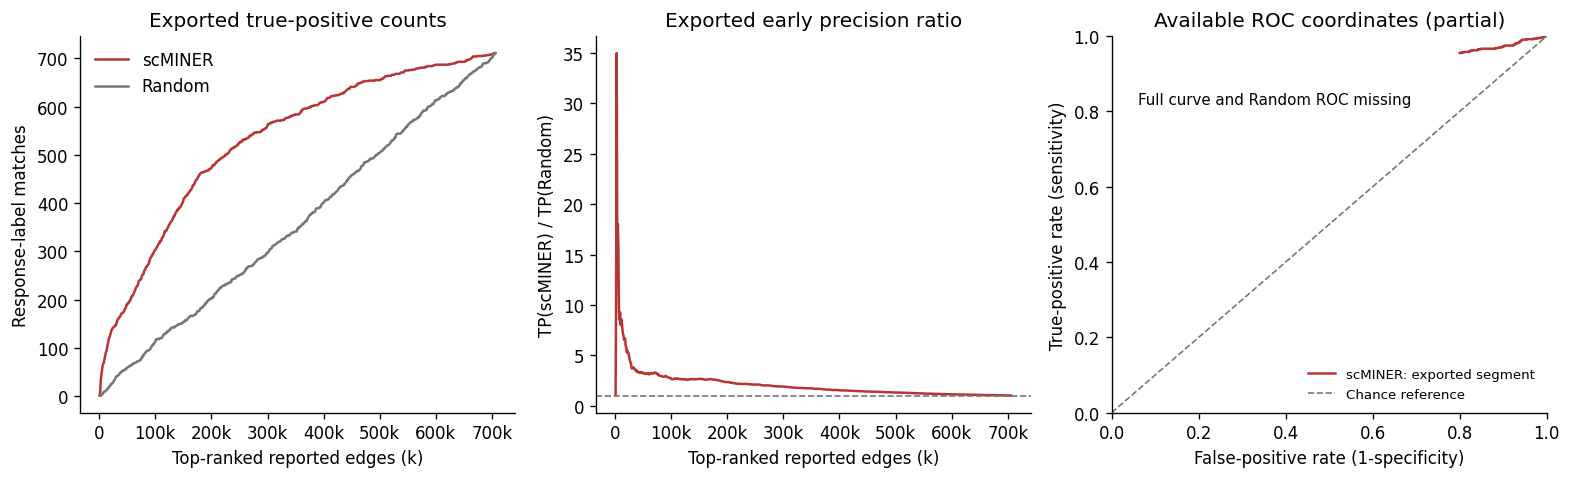

In [15]:
colors = {'scMINER': '#b73535', 'Random': '#777777'}
fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.1))
for method, group in tp_data.groupby('tp_method', sort=False):
    ordered = group.sort_values('tp_k')
    axes[0].plot(ordered['tp_k'], ordered['tp_count'], label=method, color=colors.get(method))
axes[0].set(title='Exported true-positive counts', xlabel='Top-ranked reported edges (k)', ylabel='Response-label matches')
axes[0].legend(frameon=False)
axes[1].plot(epr_data['epr_k'], epr_data['epr_reported'], color=colors['scMINER'])
axes[1].axhline(1, linestyle='--', color='#777777', linewidth=1)
axes[1].set(title='Exported early precision ratio', xlabel='Top-ranked reported edges (k)', ylabel='TP(scMINER) / TP(Random)')
for ax in axes[:2]:
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value / 1000:g}k' if value else '0'))
for method, group in roc_plot_groups.items():
    axes[2].plot(group['roc_fpr'], group['roc_tpr'], color=colors.get(method), label=f'{method}: exported segment')
axes[2].plot([0, 1], [0, 1], '--', color='#777777', linewidth=1, label='Chance reference')
axes[2].set(title='Available ROC coordinates (partial)', xlabel='False-positive rate (1-specificity)',
            ylabel='True-positive rate (sensitivity)', xlim=(0, 1), ylim=(0, 1))
axes[2].text(0.06, 0.82, 'Full curve and Random ROC missing', fontsize=9)
axes[2].legend(frameon=False, fontsize=8, loc='lower right')
fig.tight_layout()
plt.show()

### Some edge identities are available elsewhere in the workbook

`Figure_6c` contains a representative subnetwork with source, target, MI, sign, and order. This is useful for understanding an individual panel, but it is not the complete pooled candidate list behind Figure 6a. Do not use this subset as a replacement for the missing full network.

In [16]:
representative_network = pd.read_excel(WORKBOOK_PATH, sheet_name='Figure_6c', engine='openpyxl')
print('Representative network rows:', len(representative_network))
display(representative_network.head())
display(representative_network['Source'].value_counts().rename('reported targets in this panel').to_frame())

Representative network rows: 188


,Source,Target,Mutual_Information,Sign,Order
0,IFNGR2,TNFAIP6,0.7733,1,1
1,IFNGR2,SOD2,0.7724,1,2
2,IFNGR2,FTH1,0.7539,1,3
3,IFNGR2,LYN,0.7481,1,4
4,IFNGR2,NCF1,0.7460,1,5


,reported targets in this panel
Source,
IFNGR2,188


## 8. How do expression data become Figure 6a summaries?

There are two upstream branches: **NT-cell network inference** produces ranked edges, while **perturbed-versus-NT differential expression** produces response labels. They meet at the ranking evaluation. The workbook itself is a downstream summary, not a direct conversion of H5AD expression into Excel.

| Stage | Evidence and calculation | What is missing or different here |
| --- | --- | --- |
| Cell/gene QC and eligible perturbations | Paper describes QC and perturbation filtering | The scoped scripts load prepared `sce_filt_results_proc.Rdata` and `filt_targets_results.Rdata`; their creation is absent |
| NT expression preparation and supercells | Paper describes log2(1+CPM), SuperCell, and SJARACNe inputs | The scoped processing script loads `supercells_sce_NT.Rdata`; it does not create it |
| Network and ranking | Processing script reads the SIG consensus network and sorts MI descending | Full consensus adjacency and saved `NT_SIG_net.Rdata` are missing |
| Response effects | `DE_compute.Rmd` compares each selected perturbation against NT using `scran::findMarkers` | Not the GEO FR-Perturb CSV and not our illustrative means |
| Response labels | Active plotting code uses strict `abs(logFC.NT) > 0.25`, then intersects truth sources with SIG annotations | No active p-value/FDR filter in this code; the paper states an inclusive threshold |
| Candidate universe | Every reported network edge is tested for membership in the response-label set | Nonreported edges are absent; predictions are not explicitly restricted to evaluable truth sources |
| Random order | The SIG script permutes the same edge list, with R seed 1 | Not random endpoint reassignment; another RNG implementation need not reproduce the permutation |
| TP and EPR | Top-k counts at k = 1000, 2000, ...; ratio of method counts | The EPR export is checkable from workbook TP values |
| ROC | Uses ordinal ranks with lower rank predicting a positive response label | Complete arrays are used in the author plot, but the workbook export is partial |
| Final XLSX packaging | Public scripts save RData and PNG/PDF figures | No XLSX export step appears in these three scripts; the exact packaging/truncation cause is unknown |

Code references: [DE inputs/computation](https://github.com/jyyulab/scMINER_analysis/blob/c39f0aaffc22be81ae425adf9e7617504ae9ee33/network_inference/CROP_Seq_GRN_evaluation/Yao_Regev_Cleary/DE_compute.Rmd#L38-L80), [MI sorting](https://github.com/jyyulab/scMINER_analysis/blob/c39f0aaffc22be81ae425adf9e7617504ae9ee33/network_inference/CROP_Seq_GRN_evaluation/Yao_Regev_Cleary/process_nets_compute_GSEA.Rmd#L1111-L1137), [response labels and evaluation](https://github.com/jyyulab/scMINER_analysis/blob/c39f0aaffc22be81ae425adf9e7617504ae9ee33/network_inference/CROP_Seq_GRN_evaluation/Yao_Regev_Cleary/DE_plot_ROC.Rmd#L63-L126), [complete ROC plotting arrays](https://github.com/jyyulab/scMINER_analysis/blob/c39f0aaffc22be81ae425adf9e7617504ae9ee33/network_inference/CROP_Seq_GRN_evaluation/Yao_Regev_Cleary/DE_plot_ROC.Rmd#L229-L284).

Do not equate the script's `sig_0.001` directory label with a consensus cutoff: per-subsample and consensus thresholds are separate settings, and the actual inference command is not shown in that script.

In [17]:
def show_author_lines(filename, first, last):
    path = DATA_DIR / filename
    print(f'\n{filename}, lines {first}-{last}:')
    print(f'{AUTHOR_CODE_URL}/{filename}#L{first}-L{last}')
    if not path.is_file():
        print('Local script absent; use the pinned source link above.')
        return
    lines = path.read_text(encoding='utf-8-sig').splitlines()
    for number in range(first, min(last, len(lines)) + 1):
        print(f'{number:4d}: {lines[number - 1]}')

show_author_lines('DE_compute.Rmd', 64, 75)
show_author_lines('DE_plot_ROC.Rmd', 79, 126)
show_author_lines('DE_plot_ROC.Rmd', 229, 236)


DE_compute.Rmd, lines 64-75:
https://github.com/jyyulab/scMINER_analysis/blob/c39f0aaffc22be81ae425adf9e7617504ae9ee33/network_inference/CROP_Seq_GRN_evaluation/Yao_Regev_Cleary/DE_compute.Rmd#L64-L75
  64: targets = sel_tar_per_sample$GSM6858449$NT
  65: DE_res = lapply(targets, function(target) {
  66:   ids = (colData(sce3_filt)$Guides_collapsed_by_gene == "non-targeting") | (colData(sce3_filt)$Guides_collapsed_by_gene == target);
  67:   sce = sce3_filt[,ids];
  68:   grp = 1:dim(sce)[2];
  69:   grp[colData(sce)$Guides_collapsed_by_gene == "non-targeting"] = "NT";
  70:   grp[colData(sce)$Guides_collapsed_by_gene == target] = target;
  71:   markers <- findMarkers(sce, groups = grp);
  72:   return(markers)})
  73: names(DE_res) <- targets
  74: ```
  75: 

DE_plot_ROC.Rmd, lines 79-126:
https://github.com/jyyulab/scMINER_analysis/blob/c39f0aaffc22be81ae425adf9e7617504ae9ee33/network_inference/CROP_Seq_GRN_evaluation/Yao_Regev_Cleary/DE_plot_ROC.Rmd#L79-L126
  79: #names(DE_genes

In [18]:
prepared_inputs = {
    'sce_filt_results_proc.Rdata': 'Filtered/prepared single-cell expression',
    'filt_targets_results.Rdata': 'Author-selected perturbations',
    'supercells_sce_NT.Rdata': 'NT supercells',
    'DE_res_GSM6858449_NT.Rdata': 'scran differential-expression results',
    'NT_SIG_net.Rdata': 'Full MI-ranked SIG network',
    'tf_sigs_hg.RData': 'TF/SIG annotations used for evaluation',
}
available_files = {path.name.casefold(): path for path in DATA_DIR.rglob('*') if path.is_file()}
display(pd.DataFrame([{'input': name, 'purpose': purpose, 'available_locally': name.casefold() in available_files}
                      for name, purpose in prepared_inputs.items()]))

,input,purpose,available_locally
0,sce_filt_results_proc.Rdata,Filtered/prepared single-cell expression,False
1,filt_targets_results.Rdata,Author-selected perturbations,False
2,supercells_sce_NT.Rdata,NT supercells,False
3,DE_res_GSM6858449_NT.Rdata,scran differential-expression results,False
4,NT_SIG_net.Rdata,Full MI-ranked SIG network,False
5,tf_sigs_hg.RData,TF/SIG annotations used for evaluation,False


## 9. What we can and cannot conclude

We can inspect cells, genes, guide multiplicity, clean controls, count normalization, and sampled assignment-matrix consistency. We can inspect the FR-Perturb schema, redraw workbook summaries, and reproduce its EPR arithmetic. We can trace the public ranking-evaluation logic.

We cannot recover the complete Figure 6a ROC/AUROC, full ranked network, exact perturbation-eligibility list, or missing prepared expression objects from these summaries alone. The actual XLSX assembly procedure is undocumented in the inspected scripts. Exact reproduction needs the author-prepared inputs or a separately specified public-data reconstruction.

For future benchmarking, response labels measure functional consequences that can include indirect effects. They are not a direct-edge gold standard. This notebook makes no claim about whether pre-PR #70 or PR #70 performs better.

The next cell closes the read-only H5AD handle. If an earlier cell fails, close it manually or restart the kernel before moving the file.

In [19]:
adata.file.close()
print('Closed the H5AD backing file. Input files were not modified.')

Closed the H5AD backing file. Input files were not modified.
